In [11]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from typing import Tuple, Dict

In [2]:
df = pd.read_parquet("../data/processed/clean.parquet")

In [6]:
INK = "#1f2933"
MUTED = "#6b7280"
GRID = "#e5e7eb"
BASE = "#4a78b0"
ACCENT = "#e07a2f"

# 3.1. Best selling items

In [3]:
by_product = (
    df.groupby(["StockCode", "Description"])
     .agg(Quantity=("Quantity", "sum"),
          Revenue=("TotalPrice", "sum"),
          Customers=("CustomerID", "nunique"))
     .reset_index()
)

## By Revenue

In [4]:
by_product.nlargest(10, "Revenue")[["Description", "Revenue", "Customers"]]

,Description,Revenue,Customers
1846,REGENCY CAKESTAND 3 TIER,277656.25,1314
4723,WHITE HANGING HEART T-LIGHT HOLDER,247048.01,1490
3263,"PAPER CRAFT , LITTLE BIRDIE",168469.60,1
4698,JUMBO BAG RED RETROSPOT,134307.44,860
4429,ASSORTED COLOUR BIRD ORNAMENT,124351.86,1010
3606,PARTY BUNTING,103283.38,894
2761,MEDIUM CERAMIC TOP STORAGE JAR,81416.73,138
1437,PAPER CHAIN KIT 50'S CHRISTMAS,76598.18,896
3908,CHILLI LIGHTS,69084.30,304
4702,JUMBO BAG STRAWBERRY,64127.77,549


## By Quantity

In [5]:
by_product.nlargest(10, "Quantity")[["Description", "Quantity", "Customers"]]

,Description,Quantity,Customers
4006,WORLD WAR 2 GLIDERS ASSTD DESIGNS,105185,482
4723,WHITE HANGING HEART T-LIGHT HOLDER,91757,1490
3263,"PAPER CRAFT , LITTLE BIRDIE",80995,1
4429,ASSORTED COLOUR BIRD ORNAMENT,78234,1010
2761,MEDIUM CERAMIC TOP STORAGE JAR,77916,138
4698,JUMBO BAG RED RETROSPOT,74224,860
114,BROCADE RING PURSE,70082,215
1347,PACK OF 60 PINK PAISLEY CAKE CASES,54592,767
4568,60 TEATIME FAIRY CAKE CASES,52828,822
655,PACK OF 72 RETRO SPOT CAKE CASES,45129,632


# 3.2 Pareto analysis

1,146 products (21.7% assortment) = 80% revenue


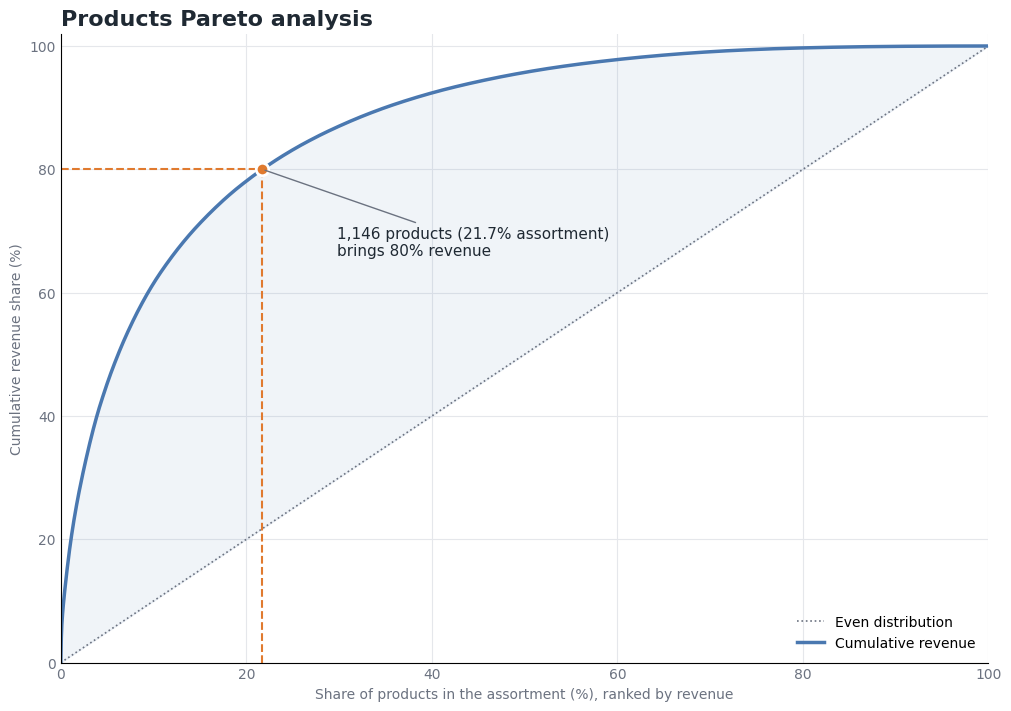

In [7]:
s = by_product.sort_values("Revenue", ascending=False).reset_index(drop=True)
s["Cumulatively %"] = s["Revenue"].cumsum() / s["Revenue"].sum() * 100
s["Product share %"] = (s.index + 1) / len(s) * 100

until80 = int((s["Cumulatively %"] < 80).sum()) + 1
stake80 = until80 / len(s) * 100
print(f"{until80:,} products ({stake80:.1f}% assortment) = 80% revenue")

fig, ax = plt.subplots(figsize=(10, 7), constrained_layout=True)

x = np.concatenate([[0], s["Product share %"]])
y = np.concatenate([[0], s["Cumulatively %"]])

ax.plot(
    [0, 100],
    [0, 100], 
    color=MUTED, 
    linestyle=":", 
    linewidth=1.2,
    label="Even distribution"
)
ax.plot(x, y, color=BASE, linewidth=2.5, label="Cumulative revenue")
ax.fill_between(x, y, x, color=BASE, alpha=0.08)

ax.hlines(80, 0, stake80, color=ACCENT, linestyle="--", linewidth=1.5)
ax.vlines(stake80, 0, 80, color=ACCENT, linestyle="--", linewidth=1.5)
ax.plot(
    stake80, 
    80, 
    "o", 
    color=ACCENT, 
    markersize=9,
    markeredgecolor="white", 
    markeredgewidth=2
)
ax.annotate(
    f"{until80:,} products ({stake80:.1f}% assortment)\nbrings 80% revenue",
    xy=(stake80, 80), 
    xytext=(stake80 + 8, 66), 
    fontsize=11, 
    color=INK,
    arrowprops=dict(arrowstyle="-", color=MUTED)
)

ax.set_xlim(0, 100)
ax.set_ylim(0, 102)
ax.set_title("Products Pareto analysis", loc="left", fontsize=16, fontweight="bold", color=INK)
ax.set_xlabel("Share of products in the assortment (%), ranked by revenue", color=MUTED)
ax.set_ylabel("Cumulative revenue share (%)", color=MUTED)

ax.tick_params(colors=MUTED, length=0)
ax.grid(True, color=GRID, linewidth=0.8)
ax.set_axisbelow(True)

for side in ("top", "right"):
    ax.spines[side].set_visible(False)

ax.legend(frameon=False, loc="lower right")
plt.show()

# 3.1 RFM Analysis

In [8]:
reference_date = df["InvoiceDate"].max() + pd.Timedelta(days=1)
print(f"Reference date: {reference_date}")

Reference date: 2011-12-10 12:50:00


In [9]:
rfm = (
    df.groupby("CustomerID")
     .agg(Recency=("InvoiceDate", lambda s: (reference_date - s.max()).days),
          Frequency=("InvoiceNo", "nunique"), 
          Monetary=("TotalPrice", "sum"))    
     .reset_index()
)

rfm["Monetary"] = rfm["Monetary"].round(2)
print(f"Number of customers in RFM table: {len(rfm):,}")
rfm.head(10)

Number of customers in RFM table: 5,852


,CustomerID,Recency,Frequency,Monetary
0,12346,326,3,77352.96
1,12347,2,8,4921.53
2,12348,75,5,1658.40
3,12349,19,3,3678.69
4,12350,310,1,294.40
5,12351,375,1,300.93
6,12352,36,9,1729.54
7,12353,204,2,406.76
8,12354,232,1,1079.40
9,12355,214,2,947.61


In [13]:
def get_mean_median_max(column: str) -> Dict:
    mean = round(rfm[column].mean(), 2)
    median = round(rfm[column].median(), 2)
    max = round(rfm[column].max(), 2)

    return {
        "Column": column,
        "Mean": mean,
        "Median": median,
        "Max": max
    }

l = [
    get_mean_median_max("Recency"),
    get_mean_median_max("Frequency"),
    get_mean_median_max("Monetary"),
]

df_mean_median_max = pd.DataFrame(l)
df_mean_median_max

,Column,Mean,Median,Max
0,Recency,200.20,95.00,739.00
1,Frequency,6.25,3.00,373.00
2,Monetary,2916.71,856.02,580987.04


# 3.4 Scoring (1–5) and customer segmentation

In [14]:
def quintiles(series: pd.Series, ascending: bool) -> pd.qcut:
    rang = series.rank(method="first", ascending=ascending)

    return pd.qcut(rang, 5, labels=[1, 2, 3, 4, 5]).astype(int)

rfm["R"] = quintiles(rfm["Recency"],   ascending=False)
rfm["F"] = quintiles(rfm["Frequency"], ascending=True)
rfm["M"] = quintiles(rfm["Monetary"],  ascending=True)

rfm[["CustomerID", "Recency", "Frequency", "Monetary", "R", "F", "M"]].head(10)

,CustomerID,Recency,Frequency,Monetary,R,F,M
0,12346,326,3,77352.96,2,3,5
1,12347,2,8,4921.53,5,4,5
2,12348,75,5,1658.40,3,4,4
3,12349,19,3,3678.69,4,3,5
4,12350,310,1,294.40,2,1,2
5,12351,375,1,300.93,2,1,2
6,12352,36,9,1729.54,4,5,4
7,12353,204,2,406.76,2,2,2
8,12354,232,1,1079.40,2,1,3
9,12355,214,2,947.61,2,2,3


## Segment assignment based on R and F score

In [15]:
segment_map = {
    r"[1-2][1-2]": "Lost",
    r"[1-2][3-4]": "At Risk",
    r"[1-2]5":     "Cannot Lose Them",
    r"3[1-2]":     "Asleep",
    r"33":         "Need Attention",
    r"[3-4][4-5]": "Loyal Customers",
    r"41":         "Promising",
    r"51":         "New Customers",
    r"[4-5][2-3]": "Potential Loyalists",
    r"5[4-5]":     "Champions",
}

rf = rfm["R"].astype(str) + rfm["F"].astype(str)
rfm["Segment"] = rf.replace(segment_map, regex=True)

summary = (
    rfm.groupby("Segment")
    .agg(Customers=("CustomerID", "count"), 
         Revenue=("Monetary", "sum"))
)
summary["Share of Customers %"] = summary["Customers"] / summary["Customers"].sum() * 100
summary["Share of Revenue %"] = summary["Revenue"] / summary["Revenue"].sum() * 100

summary.round(1).sort_values("Share of Revenue %", ascending=False)

,Customers,Revenue,Share of Customers %,Share of Revenue %
Segment,,,,
Champions,830,8781126.4,14.2,51.4
Loyal Customers,1151,4658851.8,19.7,27.3
At Risk,759,1094280.6,13.0,6.4
Potential Loyalists,710,811734.6,12.1,4.8
Lost,1510,620443.0,25.8,3.6
Cannot Lose Them,72,503405.1,1.2,2.9
Need Attention,268,338417.5,4.6,2.0
Asleep,385,205868.2,6.6,1.2
Promising,116,36670.6,2.0,0.2


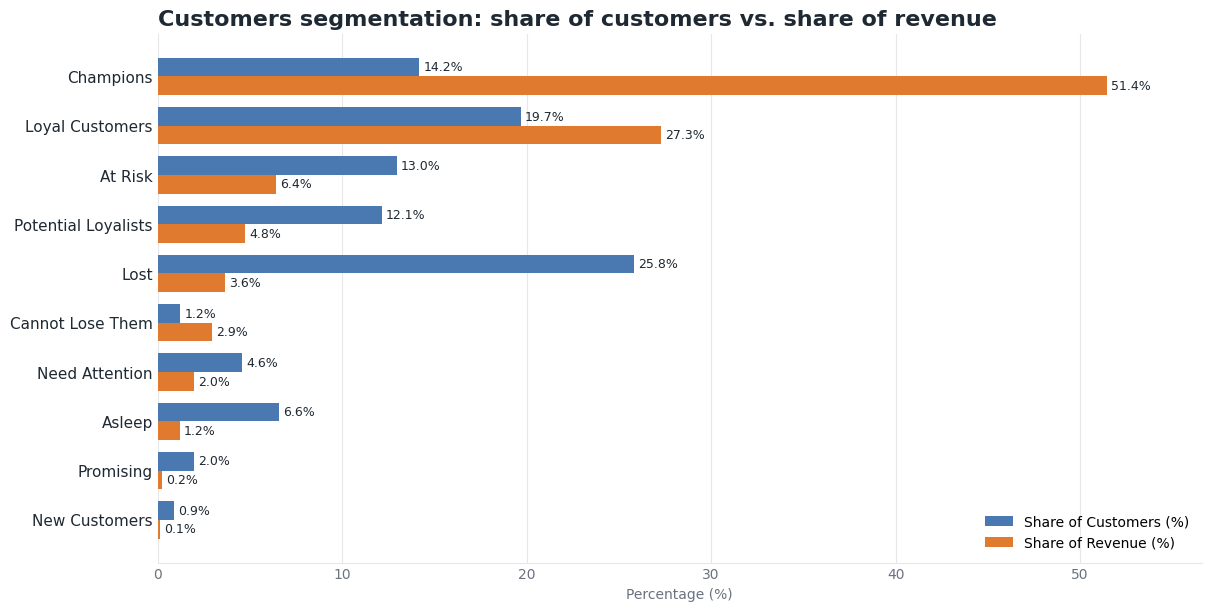

In [16]:
summary_graph = summary.sort_values("Share of Revenue %", ascending=True)

fig, ax = plt.subplots(figsize=(12, 6), constrained_layout=True)
y = np.arange(len(summary_graph))
height = 0.38

b1 = ax.barh(
    y + height / 2, 
    summary_graph["Share of Customers %"], 
    height=height,
    label="Share of Customers (%)", 
    color=BASE
)
b2 = ax.barh(
    y - height / 2, 
    summary_graph["Share of Revenue %"], 
    height=height,
    label="Share of Revenue (%)", 
    color=ACCENT
)

ax.bar_label(b1, fmt="%.1f%%", padding=3, fontsize=9, color=INK)
ax.bar_label(b2, fmt="%.1f%%", padding=3, fontsize=9, color=INK)

ax.set_yticks(y)
ax.set_yticklabels(summary_graph.index, fontsize=11, color=INK)
ax.set_xlabel("Percentage (%)", color=MUTED)
ax.set_title(
    "Customers segmentation: share of customers vs. share of revenue",
    loc="left", 
    fontsize=16, 
    fontweight="bold", 
    color=INK
)
ax.margins(x=0.1)

ax.tick_params(axis="x", colors=MUTED, length=0)
ax.tick_params(axis="y", length=0)
ax.set_axisbelow(True)
ax.xaxis.grid(True, color=GRID, linewidth=0.8)

for side in ("top", "right", "left"):
    ax.spines[side].set_visible(False)
    
ax.spines["bottom"].set_color(GRID)

ax.legend(frameon=False, loc="lower right")
plt.show()

In [17]:
rfm.to_parquet("../data/processed/rfm.parquet", index=False)